In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
'''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
'''
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

2025-12-12 00:08:55.269217: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-12-12 00:08:55.278769: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-12-12 00:08:55.318914: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-12-12 00:08:55.318953: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-12-12 00:08:55.318984: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

"\nfor dirname, _, filenames in os.walk('/kaggle/input'):\n    for filename in filenames:\n        print(os.path.join(dirname, filename))\n"

In [2]:
df= pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")
score_cols = [f"scores_{i}" for i in range(23)]
df = df.drop(columns=score_cols)

In [3]:
df = df.sort_values(by="timestamp").reset_index(drop=True)


In [4]:
df['close_sign'] = (df['close'] > df['close'].shift(1)).astype(int)
df['close_diff'] = (df['close'].diff()).astype(float)

In [5]:
df['close_diff'] = df['close_diff'].fillna(0)


In [6]:
df.columns

Index(['timestamp', 'symbol', 'open', 'high', 'low', 'close', 'volume',
       'sma_10', 'sma_50', 'ema_20', 'rsi_14', 'macd', 'macd_signal',
       'macd_hist', 'volatility_20', 'target_up_next', 'day', 'hour',
       'sum_of_scores', 'avg_of_scores', 'normalized_avg', 'max_of_scores',
       'min_of_scores', 'normalized_min', 'normalized_max',
       'avg_score_of_normalized_min', 'avg_score_of_normalized_max',
       'avg_score_of_normalized_avg', 'close_sign', 'close_diff'],
      dtype='object')

In [7]:
df['close_sign'] 

0       0
1       1
2       0
3       0
4       1
       ..
1032    0
1033    1
1034    1
1035    0
1036    0
Name: close_sign, Length: 1037, dtype: int64

# LSTM

## Close price with avg min, and max score of all. 

In [8]:
# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1, target_col=0):
    dataX, dataY = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), :]          # full feature window
        dataX.append(a)
        dataY.append(dataset[i + look_back, target_col])
    return np.array(dataX), np.array(dataY)

# fix random seed for reproducibility
np.random.seed(5)


# take close price column[5]
#all_y = df["close"].values
dataset = df[['close_sign','avg_score_of_normalized_min', 'avg_score_of_normalized_max',
       'avg_score_of_normalized_avg']].values
#dataset=all_y.reshape(-1, 1)
target_col = 0 # target label is Close



# normalize ALL features
#scaler = MinMaxScaler(feature_range=(0, 1))
#dataset = scaler.fit_transform(dataset)

# split into train and test sets, 50% test data
train_size = int(len(dataset) * 0.7)
train, test = dataset[0:train_size, :], dataset[train_size:, :]

# create supervised dataset
look_back = 15
trainX, trainY = create_dataset(train, look_back, target_col)
testX, testY = create_dataset(test, look_back, target_col)

# reshape input to be [samples, time steps, features]
n_features = dataset.shape[1]
trainX = trainX.reshape(trainX.shape[0], look_back, n_features)
testX = testX.reshape(testX.shape[0], look_back, n_features)

# create and fit the LSTM network, optimizer=adam, 25 neurons, dropout 0.1
model = Sequential()
model.add(LSTM(25, input_shape=(look_back, n_features)))
model.add(Dropout(0.1))
model.add(Dense(1, activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])



2025-12-12 00:09:23.310496: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [9]:
model.fit(trainX, trainY, epochs=1000, batch_size=240, verbose=1)

Epoch 1/1000
3/3 [==============================] - 2s 9ms/step - loss: 0.6961 - accuracy: 0.5021
Epoch 2/1000
3/3 [==============================] - 0s 8ms/step - loss: 0.6950 - accuracy: 0.4894
Epoch 3/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6928 - accuracy: 0.4979
Epoch 4/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6938 - accuracy: 0.4824
Epoch 5/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6938 - accuracy: 0.4937
Epoch 6/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6923 - accuracy: 0.5007
Epoch 7/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6922 - accuracy: 0.5134
Epoch 8/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6919 - accuracy: 0.5233
Epoch 9/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6933 - accuracy: 0.5176
Epoch 10/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6915 - accuracy: 0.5247
Epoch 11/1000
3/3 [

3/3 [==============================] - 0s 7ms/step - loss: 0.6873 - accuracy: 0.5374
Epoch 84/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6869 - accuracy: 0.5430
Epoch 85/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6860 - accuracy: 0.5317
Epoch 86/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6857 - accuracy: 0.5472
Epoch 87/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6867 - accuracy: 0.5317
Epoch 88/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6862 - accuracy: 0.5501
Epoch 89/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6841 - accuracy: 0.5331
Epoch 90/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6842 - accuracy: 0.5402
Epoch 91/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6880 - accuracy: 0.5402
Epoch 92/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6857 - accuracy: 0.5444
Epoch 93/1000
3/3 [=====

3/3 [==============================] - 0s 6ms/step - loss: 0.6801 - accuracy: 0.5585
Epoch 166/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6805 - accuracy: 0.5642
Epoch 167/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6807 - accuracy: 0.5571
Epoch 168/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6798 - accuracy: 0.5670
Epoch 169/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6818 - accuracy: 0.5614
Epoch 170/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6786 - accuracy: 0.5585
Epoch 171/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6813 - accuracy: 0.5501
Epoch 172/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6797 - accuracy: 0.5656
Epoch 173/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6807 - accuracy: 0.5585
Epoch 174/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6793 - accuracy: 0.5656
Epoch 175/1000


3/3 [==============================] - 0s 6ms/step - loss: 0.6742 - accuracy: 0.5811
Epoch 248/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6729 - accuracy: 0.5755
Epoch 249/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6696 - accuracy: 0.5825
Epoch 250/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6733 - accuracy: 0.5867
Epoch 251/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6724 - accuracy: 0.5825
Epoch 252/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6731 - accuracy: 0.5867
Epoch 253/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6698 - accuracy: 0.6008
Epoch 254/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6730 - accuracy: 0.5910
Epoch 255/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6735 - accuracy: 0.5867
Epoch 256/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6703 - accuracy: 0.5783
Epoch 257/1000


3/3 [==============================] - 0s 7ms/step - loss: 0.6627 - accuracy: 0.5938
Epoch 330/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6603 - accuracy: 0.6008
Epoch 331/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6615 - accuracy: 0.5938
Epoch 332/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6613 - accuracy: 0.5910
Epoch 333/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6558 - accuracy: 0.5938
Epoch 334/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6619 - accuracy: 0.5797
Epoch 335/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6602 - accuracy: 0.5797
Epoch 336/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6568 - accuracy: 0.6037
Epoch 337/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6573 - accuracy: 0.6135
Epoch 338/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.6558 - accuracy: 0.6079
Epoch 339/1000


3/3 [==============================] - 0s 7ms/step - loss: 0.6294 - accuracy: 0.6375
Epoch 412/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6292 - accuracy: 0.6375
Epoch 413/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6269 - accuracy: 0.6262
Epoch 414/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6262 - accuracy: 0.6544
Epoch 415/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6231 - accuracy: 0.6474
Epoch 416/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6230 - accuracy: 0.6389
Epoch 417/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6244 - accuracy: 0.6305
Epoch 418/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6237 - accuracy: 0.6206
Epoch 419/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6249 - accuracy: 0.6333
Epoch 420/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.6243 - accuracy: 0.6432
Epoch 421/1000


... (3 outputs left out)

3/3 [==============================] - 0s 6ms/step - loss: 0.3991 - accuracy: 0.8152
Epoch 740/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.4062 - accuracy: 0.8181
Epoch 741/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.3955 - accuracy: 0.8110
Epoch 742/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.3967 - accuracy: 0.8096
Epoch 743/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.3913 - accuracy: 0.8166
Epoch 744/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.4103 - accuracy: 0.7997
Epoch 745/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.3918 - accuracy: 0.8265
Epoch 746/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.4017 - accuracy: 0.8054
Epoch 747/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.3899 - accuracy: 0.8124
Epoch 748/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.4053 - accuracy: 0.8096
Epoch 749/1000


3/3 [==============================] - 0s 9ms/step - loss: 0.3421 - accuracy: 0.8491
Epoch 822/1000
3/3 [==============================] - 0s 8ms/step - loss: 0.3451 - accuracy: 0.8434
Epoch 823/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.3444 - accuracy: 0.8477
Epoch 824/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.3471 - accuracy: 0.8406
Epoch 825/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.3513 - accuracy: 0.8364
Epoch 826/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.3590 - accuracy: 0.8307
Epoch 827/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.3367 - accuracy: 0.8406
Epoch 828/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.3437 - accuracy: 0.8449
Epoch 829/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.3413 - accuracy: 0.8449
Epoch 830/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.3435 - accuracy: 0.8463
Epoch 831/1000


3/3 [==============================] - 0s 7ms/step - loss: 0.3078 - accuracy: 0.8561
Epoch 904/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.3004 - accuracy: 0.8745
Epoch 905/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.2892 - accuracy: 0.8858
Epoch 906/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.2835 - accuracy: 0.8815
Epoch 907/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.2996 - accuracy: 0.8717
Epoch 908/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.2943 - accuracy: 0.8745
Epoch 909/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.2762 - accuracy: 0.8928
Epoch 910/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.2844 - accuracy: 0.8731
Epoch 911/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.2907 - accuracy: 0.8717
Epoch 912/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.2887 - accuracy: 0.8801
Epoch 913/1000


3/3 [==============================] - 0s 6ms/step - loss: 0.2524 - accuracy: 0.8900
Epoch 986/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.2429 - accuracy: 0.9027
Epoch 987/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.2439 - accuracy: 0.8984
Epoch 988/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.2408 - accuracy: 0.8970
Epoch 989/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.2562 - accuracy: 0.8801
Epoch 990/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.2429 - accuracy: 0.9041
Epoch 991/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.2477 - accuracy: 0.8984
Epoch 992/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.2400 - accuracy: 0.8984
Epoch 993/1000
3/3 [==============================] - 0s 7ms/step - loss: 0.2409 - accuracy: 0.8928
Epoch 994/1000
3/3 [==============================] - 0s 6ms/step - loss: 0.2529 - accuracy: 0.8886
Epoch 995/1000


10/10 [==============================] - 0s 2ms/step
trainPredict::  (709, 1)
testPredict::  (296, 1)
Train Accuracy: 0.922425952045134
Test Accuracy: 0.5304054054054054
Classification Report (Test):
              precision    recall  f1-score   support

           0       0.51      0.56      0.53       142
           1       0.55      0.51      0.53       154

    accuracy                           0.53       296
   macro avg       0.53      0.53      0.53       296
weighted avg       0.53      0.53      0.53       296



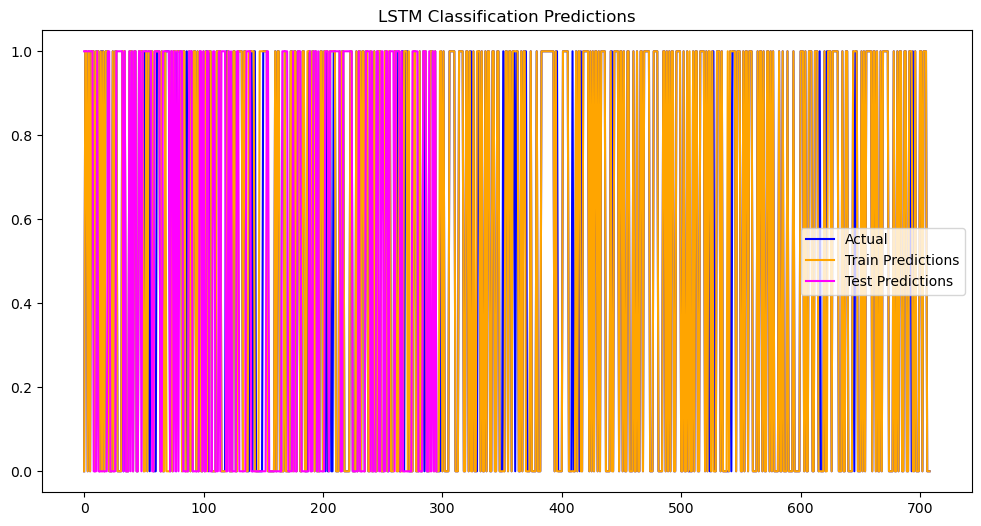

In [10]:

# predictions
trainPredict = model.predict(trainX)
testPredict = model.predict(testX)

# invert prediction scaling (only target)
'''
trainPredict = scaler.inverse_transform(
    np.repeat(trainPredict, n_features, axis=1)
)[:,target_col]

trainY_inv = scaler.inverse_transform(
    np.repeat(trainY.reshape(-1,1), n_features, axis=1)
)[:,target_col]

testPredict = scaler.inverse_transform(
    np.repeat(testPredict, n_features, axis=1)
)[:,target_col]

testY_inv = scaler.inverse_transform(
    np.repeat(testY.reshape(-1,1), n_features, axis=1)
)[:,target_col]
'''
## Cancelling normlarization
'''

trainPredict = np.repeat(trainPredict, n_features, axis=1)[:,target_col]

trainY_inv = np.repeat(trainY.reshape(-1,1), n_features, axis=1)[:,target_col]

testPredict = np.repeat(testPredict, n_features, axis=1)[:,target_col]

testY_inv = np.repeat(testY.reshape(-1,1), n_features, axis=1)[:,target_col]
'''


print("trainPredict:: ", trainPredict.shape)
print("testPredict:: ", testPredict.shape)


# Convert continuous labels to 0/1 using the same threshold as predictions
threshold = 0.5  # or whatever makes sense for your data
trainY_class = (trainY > threshold).astype(int).reshape(-1)
testY_class = (testY > threshold).astype(int).reshape(-1)

trainPredClass = (trainPredict > threshold).astype(int).reshape(-1)
testPredClass = (testPredict > threshold).astype(int).reshape(-1)

from sklearn.metrics import accuracy_score, classification_report

print("Train Accuracy:", accuracy_score(trainY_class, trainPredClass))
print("Test Accuracy:", accuracy_score(testY_class, testPredClass))
print("Classification Report (Test):")
print(classification_report(testY_class, testPredClass))


# export prediction and actual prices
#df = pd.DataFrame(data={"prediction": np.around(list(testPredict.reshape(-1)), decimals=2), "test_price": np.around(list(testPrices.reshape(-1)), decimals=2)})
#df.to_csv("lstm_result.csv", sep=';', index=None)

# plot the actual price, prediction in test data=red line, actual price=blue line
#plt.plot(testPredictPlot)
#plt.show()

plt.figure(figsize=(12,6))
plt.plot(trainY, label="Actual", color="blue")
plt.plot(trainPredClass, label="Train Predictions", color="orange")
plt.plot(testPredClass, label="Test Predictions", color="magenta")
plt.legend()
plt.title("LSTM Classification Predictions")
plt.show()


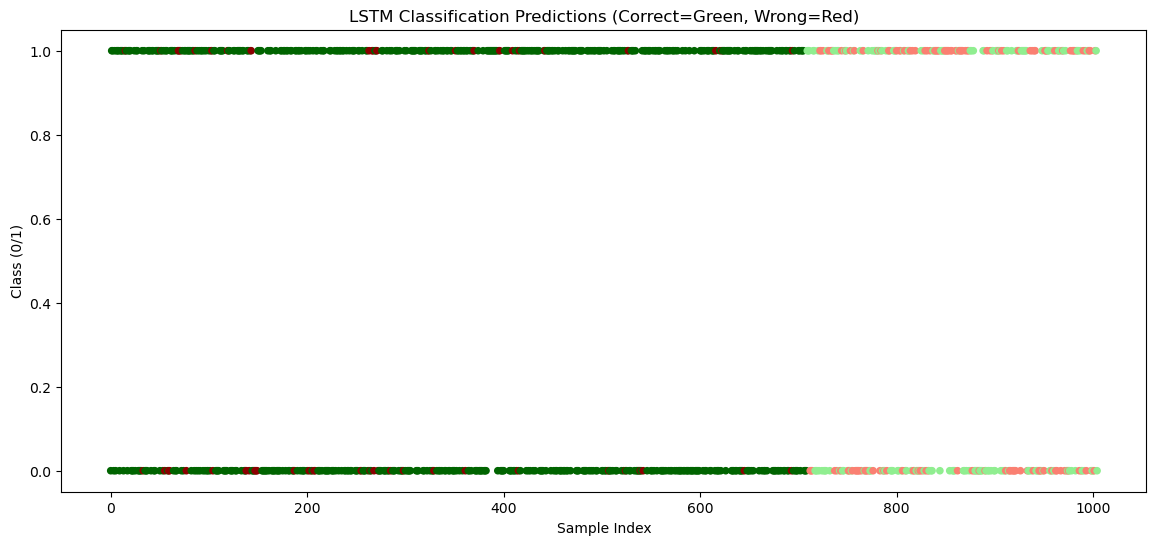

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Flatten arrays
actual = trainY_class.tolist() + testY_class.tolist()
pred_train = trainPredClass
pred_test = testPredClass

# Combine predictions and labels for plotting
predictions = np.concatenate([pred_train, pred_test])
is_train = np.array([True]*len(pred_train) + [False]*len(pred_test))

# Colors: green if correct, red if wrong; two shades for train/test
colors = []
for i, (a, p, t) in enumerate(zip(actual, predictions, is_train)):
    if a == p:
        colors.append('darkgreen' if t else 'lightgreen')
    else:
        colors.append('darkred' if t else 'salmon')

plt.figure(figsize=(14,6))
plt.scatter(range(len(actual)), actual, c=colors, s=20)
plt.xlabel("Sample Index")
plt.ylabel("Class (0/1)")
plt.title("LSTM Classification Predictions (Correct=Green, Wrong=Red)")
plt.show()


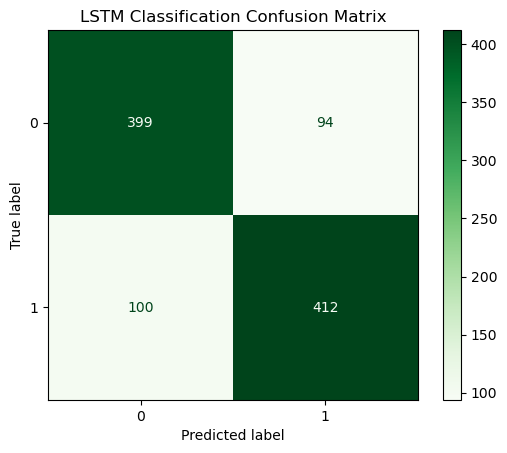

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Combine train and test if you want overall
y_true = np.concatenate([trainY_class, testY_class])
y_pred = np.concatenate([trainPredClass, testPredClass])

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Greens)
plt.title("LSTM Classification Confusion Matrix")
plt.show()


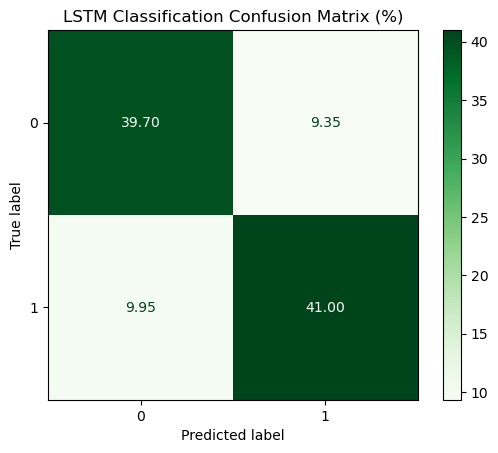

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

# Combine train and test if you want overall
y_true = np.concatenate([trainY_class, testY_class])
y_pred = np.concatenate([trainPredClass, testPredClass])

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Convert to percentages
cm_percent = cm.astype('float') / cm.sum() * 100

# Display
disp = ConfusionMatrixDisplay(confusion_matrix=cm_percent, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Greens, values_format=".2f")  # format as 2 decimal percentages
plt.title("LSTM Classification Confusion Matrix (%)")
plt.show()


In [14]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_true, y_pred)
print(f"Total Accuracy: {accuracy*100:.2f}%")

Total Accuracy: 80.70%
